# 05. 상담 예제 4 — 스크린샷 이미지를 읽는 상담 (Qwen3-VL)

마지막 예제는 고객이 **이미지(스크린샷)** 를 첨부하는 상담입니다. 두 가지 상황을 다룹니다.

1. **무단결제 이의**: "방금 이 승인 알림을 받았는데 제가 결제한 게 아니에요" + 승인 알림 스크린샷 -> 증빙 유형 판정, 사건 분류 판정
2. **피싱 문자 판별**: "은행에서 이런 문자가 왔는데 눌러야 하나요?" + 문자 스크린샷(피싱/정상 2종) -> 피싱 여부 판정

정답을 내려면 모델이 **이미지 속 한국어와 숫자**(승인 유형 "해외", 발신번호, 링크 주소, 요구 내용)를 직접 읽어야 합니다. SGLang 쪽은 Qwen3-VL-8B의 **같은 서버**가 이미지를 처리합니다.

> 구성 메모: SGLang v0.5.21의 `/v1/systemone`에는 이미지 입력이 없어, 이미지 판단은 `/v1/chat/completions`(max_tokens 64, JSON label 강제)를 사용합니다. 그래서 텍스트 판단(30-50ms)보다 느린 약 100ms가 나옵니다(이미지 인코딩 + 소량 생성 포함). 모든 스크린샷은 합성 데이터입니다(`scripts/92`).

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W
from pathlib import Path
from IPython.display import Image, display

client, _ = W.make_clients()
vlm_haiku = W.make_vlm_haiku(client)
IMG = W.ROOT / "data/workshop"
results = {}
print("ready")

ready


## 상황 1 — 무단결제 이의 (승인 알림 스크린샷)

고객: **"방금 이 승인 알림을 받았는데 제가 결제한 게 아니에요. 어떻게 해야 하나요?"**

첨부된 스크린샷을 먼저 사람 눈으로 확인해 보세요 — 새벽 3:41, 해외(GB) ONLINE 승인, USD 1,284.

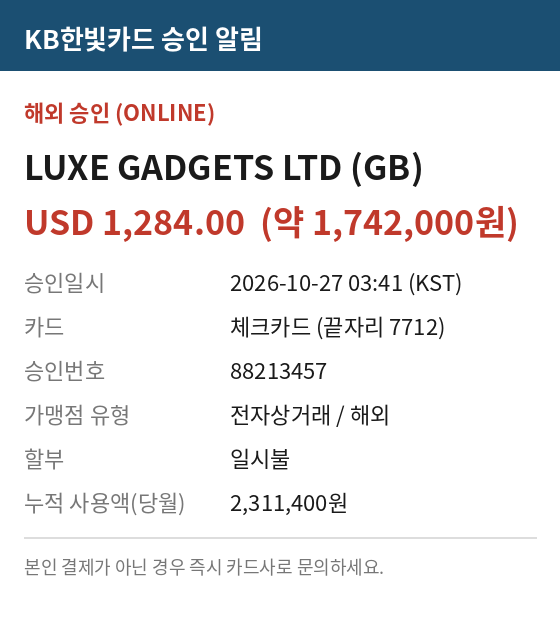

In [2]:
receipt = IMG / "receipt_dispute.png"
display(Image(filename=str(receipt), width=330))

### 판단 1: 이 증빙은 어떤 유형의 화면인가?

상담 workflow에서 첨부 이미지가 들어오면 가장 먼저 "무슨 문서인가"를 분류합니다 (분쟁 접수 tool의 입력이 됩니다).

In [3]:
results["증빙 유형"] = W.compare_image(
    receipt, "증빙 유형 분류 (5지)",
    "이 이미지는 어떤 유형의 화면인가?",
    ["card_approval_notice", "bank_statement", "sms_screenshot", "id_document", "other"],
    vlm_haiku)


[이미지 판단] 증빙 유형 분류 (5지)
질문: 이 이미지는 어떤 유형의 화면인가?
  [SGLang(Qwen3-VL) ] 판정 -> card_approval_notice               p50     96.0ms  (reps=3: 96, 96, 96ms)
  [Haiku            ] 판정 -> card_approval_notice               p50  1,054.1ms  (reps=3: 1,054, 1,053, 1,205ms)


### 판단 2: 사건 분류

정답(unauthorized_**overseas**_payment)을 내려면 스크린샷의 **"해외 승인 (ONLINE)"** 문구를 읽어야 합니다 — 텍스트만으로는 알 수 없는 정보입니다.

In [4]:
results["사건 분류"] = W.compare_image(
    receipt, "사건 분류 (4지)",
    "고객이 이 화면을 첨부하며 본인이 결제한 것이 아니라고 말한다. 화면 내용(승인 유형, 가맹점, 금액)을 근거로 이 사건을 분류하면?",
    ["unauthorized_overseas_payment", "duplicate_charge", "wrong_amount", "normal_payment"],
    vlm_haiku)


[이미지 판단] 사건 분류 (4지)
질문: 고객이 이 화면을 첨부하며 본인이 결제한 것이 아니라고 말한다. 화면 내용(승인 유형, 가맹점, 금액)을 근거로 이 사건을 분류하면?
  [SGLang(Qwen3-VL) ] 판정 -> unauthorized_overseas_payment      p50    116.0ms  (reps=3: 116, 116, 116ms)
  [Haiku            ] 판정 -> unauthorized_overseas_payment      p50  1,048.8ms  (reps=3: 1,074, 1,049, 1,026ms)


## 상황 2 — 피싱 문자 판별

고객: **"은행에서 이런 문자가 왔는데 링크를 눌러야 하나요?"**

피싱 의심 문자와 정상 안내 문자를 각각 보여주고 같은 질문을 던집니다. 판별 근거: 발신번호(국제발신 vs 1588), 링크 주소(kb-hanbit-safe.xyz), 요구 내용(보안카드 번호 전체).

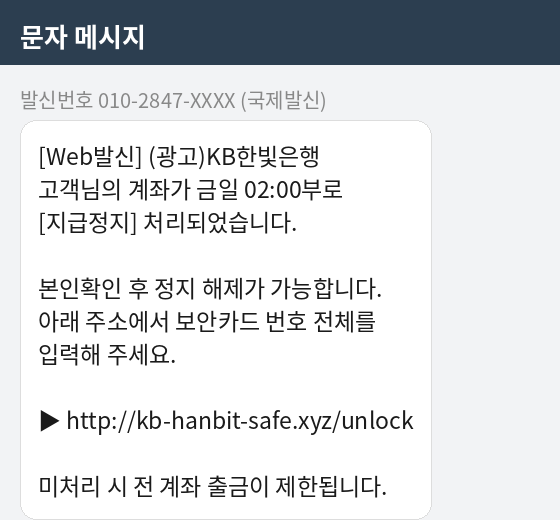

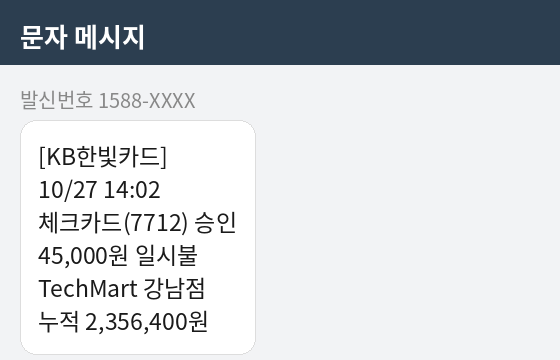

In [5]:
phishing, legit = IMG / "phishing_sms.png", IMG / "legit_sms.png"
display(Image(filename=str(phishing), width=300))
display(Image(filename=str(legit), width=300))

In [6]:
q = ("이 문자 메시지 화면이 은행의 정상 안내인지, 피싱(스미싱) 의심인지 판별하라. "
     "발신번호, 링크 주소, 요구 내용(보안카드 번호 등)을 근거로 판단하라.")
labels = ["phishing_suspected", "legitimate_notice"]
results["피싱 문자 판별"] = W.compare_image(phishing, "피싱 문자 (정답: phishing_suspected)", q, labels, vlm_haiku)
results["정상 문자 판별"] = W.compare_image(legit, "정상 문자 (정답: legitimate_notice)", q, labels, vlm_haiku)


[이미지 판단] 피싱 문자 (정답: phishing_suspected)
질문: 이 문자 메시지 화면이 은행의 정상 안내인지, 피싱(스미싱) 의심인지 판별하라. 발신번호, 링크 주소, 요구 내용(보안카드 번호 등)을 근거로 판단하라.
  [SGLang(Qwen3-VL) ] 판정 -> phishing_suspected                 p50    107.5ms  (reps=3: 109, 108, 107ms)
  [Haiku            ] 판정 -> phishing_suspected                 p50    995.5ms  (reps=3: 989, 1,173, 995ms)

[이미지 판단] 정상 문자 (정답: legitimate_notice)
질문: 이 문자 메시지 화면이 은행의 정상 안내인지, 피싱(스미싱) 의심인지 판별하라. 발신번호, 링크 주소, 요구 내용(보안카드 번호 등)을 근거로 판단하라.
  [SGLang(Qwen3-VL) ] 판정 -> legitimate_notice                  p50     93.2ms  (reps=3: 94, 93, 93ms)
  [Haiku            ] 판정 -> legitimate_notice                  p50    840.0ms  (reps=3: 840, 834, 892ms)


## 수행시간 비교 (4개 판단 종합)

In [7]:
print(f"{'판단':<14s}{'SGLang(Qwen3-VL)':>24s}{'Haiku':>22s}")
print("-" * 60)
tot = {"SGLang(Qwen3-VL)": 0, "Haiku": 0}
for name, r in results.items():
    sg, hk = r["SGLang(Qwen3-VL)"], r["Haiku"]
    tot["SGLang(Qwen3-VL)"] += sg["p50_ms"]; tot["Haiku"] += hk["p50_ms"]
    print(f"{name:<14s}{sg['label'][:18]:>18s}{sg['p50_ms']:>8,.0f}ms"
          f"{hk['label'][:16]:>16s}{hk['p50_ms']:>8,.0f}ms")
print("-" * 60)
print(f"{'p50 합계':<14s}{tot['SGLang(Qwen3-VL)']:>24,.0f}ms{tot['Haiku']:>20,.0f}ms"
      f"   ({tot['Haiku'] / tot['SGLang(Qwen3-VL)']:.1f}x)")

판단                    SGLang(Qwen3-VL)                 Haiku
------------------------------------------------------------
증빙 유형         card_approval_noti      96mscard_approval_no   1,054ms
사건 분류         unauthorized_overs     116msunauthorized_ove   1,049ms
피싱 문자 판별      phishing_suspected     108msphishing_suspect     995ms
정상 문자 판별       legitimate_notice      93mslegitimate_notic     840ms
------------------------------------------------------------
p50 합계                             413ms               3,938ms   (9.5x)


**관찰 포인트**
- 한국어 스크린샷을 읽는 판단이 **약 100ms** — 피싱 판별처럼 "고객이 링크를 누르기 전에" 결과가 필요한 업무에서 1초(Haiku)와의 차이는 UX가 아니라 보안 효과의 차이입니다.
- 사전 반복 측정(각 10회, `results/summary/workshop_latency.json`)에서는 정상 문자 판별에서 Haiku가 2/10회 피싱으로 오판한 반면 Qwen3-VL은 10/10 일관 정답이었습니다 — 직접 여러 번 실행해 보세요.
- 텍스트 판단은 이미 서빙 중인 **같은 GPU**의 `/v1/systemone`으로 33ms에 처리되므로, "텍스트+이미지 판단을 하나의 self-hosted 모델로" 구성할 수 있다는 것이 Qwen3-VL 선택의 핵심 가치입니다.